In [2]:
import pandas,json,numpy
from matplotlib import pyplot

In [3]:
# Import the data
data_directory = "../../data/"
model_json = json.load(open(data_directory+"/output/invert_organic_posterior_results_with_burial.json"))

time = model_json[0]["time"]
time_step_length = numpy.abs(numpy.diff(numpy.array(time)*model_json[0]["time_multiplier"]))

total_excess_organic_burial_constant = [model["total_excess_organic_burial_constant"] for model in model_json]
total_excess_organic_burial = [model["total_excess_organic_burial"] for model in model_json]

organic_carbon_burial = [model["organic_burial"] for model in model_json]
organic_carbon_burial_per_year = [organic_burial/time_step_length for organic_burial in organic_carbon_burial]

excess_organic_carbon_burial = [model["excess_organic_burial"] for model in model_json]
excess_organic_burial_per_year = [organic_burial/time_step_length for organic_burial in excess_organic_carbon_burial]


/tmp/ipykernel_874/4098784649.py:12: RuntimeWarning: invalid value encountered in divide
  organic_carbon_burial_per_year = [organic_burial/time_step_length for organic_burial in organic_carbon_burial]
/tmp/ipykernel_874/4098784649.py:15: RuntimeWarning: invalid value encountered in divide
  excess_organic_burial_per_year = [organic_burial/time_step_length for organic_burial in excess_organic_carbon_burial]


36082.04354055112
23204.84451147926


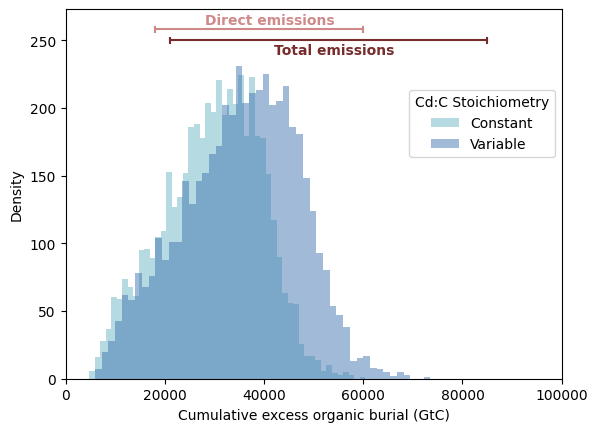

In [4]:
figure,axes = pyplot.subplots(1,1)
handle_0 = axes.hist(total_excess_organic_burial_constant,color="#6cb7c4",zorder=2,bins=50,alpha=0.5)
handle_1 = axes.hist(total_excess_organic_burial,color="#4276b1",zorder=3,bins=50,alpha=0.5)
# handle_test = axes.hist(total_excess_organic_burial_test,color="#ff0000",zorder=1,bins=50,alpha=0.5)

offset = 20

handle_emissions = axes.plot([18000,60000],[278-offset,278-offset],color="#d08989",zorder=1)
axes.plot([18000,18000],[276-offset,280-offset],color="#d08989",zorder=1)
axes.plot([60000,60000],[276-offset,280-offset],color="#d08989",zorder=1)

handle_total_emissions = axes.plot([18000+3000,60000+15000+10000],[270-offset,270-offset],color="#772c2c",zorder=1)
axes.plot([18000+3000,18000+3000],[268-offset,272-offset],color="#772c2c",zorder=1)
axes.plot([60000+15000+10000,60000+15000+10000],[268-offset,272-offset],color="#772c2c",zorder=1)

axes.text(28000,282-offset,"Direct emissions",color="#d08989",zorder=1,fontweight="bold")
axes.text(42000,260-offset,"Total emissions",color="#772c2c",zorder=1,fontweight="bold")

# axes.legend((handle_emissions[0],handle_total_emissions[0]),#type: ignore
#             ["Direct emissions Range","Total emissions range"],
#             loc="right",bbox_to_anchor=(1.0,0.7)) 

# Legend of constant vs variable stoichiometry
axes.legend((handle_0[2][0],handle_1[2][0]),
            ["Constant","Variable"],
            loc="upper right",
            bbox_to_anchor=(1.0,0.8),
            title="Cd:C Stoichiometry")

axes.set_xlabel("Cumulative excess organic burial (GtC)")
axes.set_ylabel("Density")
axes.set_xlim((0,100000))

figure.savefig("../../figures/total_excess_organic_burial.png",dpi=600)

print(numpy.median(total_excess_organic_burial))
print(numpy.std(total_excess_organic_burial)*2.0)




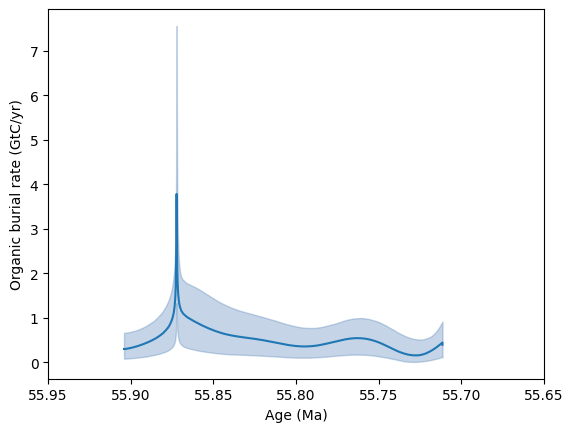

In [5]:
figure,axes = pyplot.subplots(1,1)

burial_per_year_upper = numpy.percentile(organic_carbon_burial_per_year,97.5,axis=0)
burial_per_year_median = numpy.median(organic_carbon_burial_per_year,axis=0)
burial_per_year_lower = numpy.percentile(organic_carbon_burial_per_year,2.5,axis=0)

axes.fill_between(time[1:],burial_per_year_upper,burial_per_year_lower,color="#4276b1",alpha=0.3)

axes.plot(time[1:],burial_per_year_median)

axes.set_xlabel("Age (Ma)")
axes.set_ylabel("Organic burial rate (GtC/yr)")

axes.set_xlim((55.95,55.65))


a = 5